<a href="https://colab.research.google.com/github/sonukumari-3355/Voltrelay_EV_Battery_Swap/blob/main/voltrelay_EV_battery_swap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VoltRelay Energy: Network Operations, Unit Economics & Retention Analysis

### 1. Environment Setup & Data Loading
First, I mounted Google Drive, enabled interactive DataFrame formatting in Colab, and imported the core Python libraries (`pandas`, `numpy`, `matplotlib`, and `seaborn`) needed for data cleaning, multi-table joins, and visualization.


In [1]:
from google.colab import drive, data_table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
drive.mount('/content/drive')
data_table.enable_dataframe_formatter()

Mounted at /content/drive


In [2]:
matches = glob.glob('/content/drive/MyDrive/**/fleet_partners.csv', recursive=True)
data_dir = os.path.dirname(matches[0])
print("Using Folder: ", data_dir)

Using Folder:  /content/drive/MyDrive/Hackathon Data Set | Gradient


### 2. Loading Reference & Operational Tables
Next, I loaded the six smaller reference and context tables (`fleet_partners`, `stations`, `batteries`, `riders`, `city_daily_context`, and `support_tickets`) to inspect their row counts and column structures before handling the larger transactional logs.

In [3]:
partners = pd.read_csv(f"{data_dir}/fleet_partners.csv")
stations = pd.read_csv(f"{data_dir}/stations.csv")
batteries = pd.read_csv(f"{data_dir}/batteries.csv")
riders = pd.read_csv(f"{data_dir}/riders.csv")
weather = pd.read_csv(f"{data_dir}/city_daily_context.csv")
tickets = pd.read_csv(f"{data_dir}/support_tickets.csv")

In [4]:
for name, df in [('partners', partners), ('stations', stations), ('batteries', batteries),
                 ('riders', riders), ('city_ctx', weather), ('tickets', tickets)]:
    print(f"{name:10s} -> {df.shape[0]:,} rows x {df.shape[1]} cols")

partners   -> 12 rows x 12 cols
stations   -> 152 rows x 22 cols
batteries  -> 6,500 rows x 13 cols
riders     -> 20,000 rows x 12 cols
city_ctx   -> 3,282 rows x 12 cols
tickets    -> 44,000 rows x 12 cols


### 3. Data Cleaning & Standardization
While inspecting `riders.csv`, I found inconsistent city spellings and abbreviations (such as `BLR`, `Bangalore`, `Gurgaon`, `New Delhi`, and `Bombay`). I standardized all entries into the six official operating cities and verified that internal test stations (`STN-TST-*`) were excluded from the active station list (leaving 150 active stations).

In [5]:
#checking the spelling in riders table
riders['home_city'].unique()

array(['Delhi NCR', 'Mumbai', 'Hyderabad', 'Jaipur', 'Pune', 'Bengaluru',
       'bengaluru ', 'Bangalore', 'hyderabad', 'Bombay', 'PUN', 'jaipur',
       'HYD', 'JAI', 'pune', 'BLR', 'Hyd', 'Gurgaon', 'New Delhi', 'MUM',
       'Delhi'], dtype=object)

In [6]:
riders['home_city'] = riders['home_city'].str.lower().str.strip()
riders['home_city'] = riders['home_city'].replace({'bangalore': 'Bengaluru', 'blr': 'Bengaluru', 'bengaluru': 'Bengaluru','delhi': 'Delhi NCR', 'new delhi': 'Delhi NCR', 'ncr': 'Delhi NCR', 'delhi ncr': 'Delhi NCR','hyderabad': 'Hyderabad', 'hyd': 'Hyderabad','pune': 'Pune', 'pun': 'Pune','mumbai': 'Mumbai', 'bombay': 'Mumbai', 'mum': 'Mumbai','jaipur': 'Jaipur', 'jai': 'Jaipur', 'gurgaon': 'Delhi NCR', 'delhi': 'Delhi NCR'})
print('After cleaning the spelling in riders table')
riders['home_city'].unique()

After cleaning the spelling in riders table


array(['Delhi NCR', 'Mumbai', 'Hyderabad', 'Jaipur', 'Pune', 'Bengaluru'],
      dtype=object)

In [7]:
is_test = stations['station_id'].str.startswith('STN-TST')
test_station_ids = stations[is_test]['station_id'].tolist()
stations = stations[~is_test].copy()
print('Removed test stations: ',test_station_ids)
print('Total active or real stations: ',len(stations))

Removed test stations:  ['STN-TST-01', 'STN-TST-02']
Total active or real stations:  150


### 4. Loading & Cleaning Swap Events (3.88 Million Attempts)
Because `swap_events` contains nearly 3.88 million rows, I specified memory-efficient data types (`float32` for numeric columns) when reading the file. I then applied the following cleaning rules:
1. **Timezone Bug Fix:** Corrected 139,490 timestamps logged 5 hours 30 minutes early on stations running firmware `v3.2.0` between March 10 and April 14, 2025.
2. **Offline Sync Deduplication Check:** Removed 987 offline_batch duplicate retries
3. **Sensor & Odometer Outliers:** Capped battery SOC/SOH percentages at 100% and filtered out invalid negative or >250 km distance readings into a `clean_km` column.

In [8]:
swap_file = f"{data_dir}/swap_events.csv.gz"
if not os.path.exists(swap_file):
    swap_file = f"{data_dir}/swap_events.csv"

In [9]:
col_types = {
    'event_id': 'string',
    'rider_id': 'string',
    'station_id': 'string',
    'event_type': 'string',
    'queue_wait_sec': 'float32',
    'battery_in_id': 'string',
    'battery_out_id': 'string',
    'soc_in_pct': 'float32',
    'soh_in_pct': 'float32',
    'soc_out_pct': 'float32',
    'soh_out_pct': 'float32',
    'km_since_last_swap': 'float32',
    'tariff_code': 'string',
    'list_price_inr': 'float32',
    'discount_inr': 'float32',
    'amount_charged_inr': 'float32',
    'payment_mode': 'string',
    'energy_to_recharge_kwh': 'float32',
    'station_firmware': 'string',
    'sync_mode': 'string'
}


swaps = pd.read_csv(swap_file, usecols=list(col_types.keys()) + ['event_ts'], dtype=col_types)
swaps['event_ts'] = pd.to_datetime(swaps['event_ts'])
print('Total raw swap attempts: ',len(swaps))
swaps = swaps[~swaps['station_id'].isin(test_station_ids)].copy()
print('After removing test stations: ',len(swaps))



Total raw swap attempts:  3877013
After removing test stations:  3814982


In [10]:
bugrows = ((swaps['station_firmware'] == 'v3.2.0') & (swaps['event_ts'] >= '2025-03-10') & (swaps['event_ts'] < '2025-04-15'))
swaps.loc[bugrows, 'event_ts'] = swaps.loc[bugrows, 'event_ts'] + pd.Timedelta(hours=5, minutes=30)
print('Timestamps corrected for v3.2.0: ',bugrows.sum())

Timestamps corrected for v3.2.0:  139490


In [11]:
swaps = swaps.sort_values(['rider_id', 'station_id', 'event_ts'])
seconds_since_prev = swaps.groupby(['rider_id', 'station_id'])['event_ts'].diff().dt.total_seconds()
duplicate = (swaps['sync_mode'] == 'offline_batch') & (seconds_since_prev <= 180)
swaps = swaps[~duplicate].copy()
print('Removed offline duplicates: ',duplicate.sum())
swaps['soc_in_pct'] = swaps['soc_in_pct'].clip(upper=100)
swaps['soh_in_pct'] = swaps['soh_in_pct'].clip(upper=100)
swaps['soc_out_pct'] = swaps['soc_out_pct'].clip(upper=100)
swaps['soh_out_pct'] = swaps['soh_out_pct'].clip(upper=100)


Removed offline duplicates:  987


In [12]:
valid_km = (swaps['km_since_last_swap'] >= 0) & (swaps['km_since_last_swap'] <= 250)
swaps['clean_km'] = np.where(valid_km, swaps['km_since_last_swap'], np.nan)
swaps['month'] = swaps['event_ts'].dt.to_period('M').astype(str)
swaps['hour'] = swaps['event_ts'].dt.hour
swaps['date'] = swaps['event_ts'].dt.date
print('Final clean swap rows: ',len(swaps))

Final clean swap rows:  3813995


### 5. Saving Cleaned Datasets
To avoid re-running the 3.88M-row cleaning pipeline if the runtime disconnects, I saved the cleaned swaps table in Parquet format alongside the cleaned stations and riders CSVs.

In [13]:
save_folder = '/content/drive/MyDrive/voltreplay_clean'
os.makedirs(save_folder, exist_ok=True)

swaps.to_parquet(f"{save_folder}/clean_swaps.parquet", index=False)
stations.to_csv(f"{save_folder}/clean_stations.csv", index=False)
riders.to_csv(f"{save_folder}/clean_riders.csv", index=False)
print('Saved clean files to: ',save_folder)

Saved clean files to:  /content/drive/MyDrive/voltreplay_clean


---
## Core Question 1: Network Performance & Margin Trends Over Time

To evaluate whether VoltRelay's growth is profitable, I joined station metadata (`stations.csv`) and rider profiles (`riders.csv`) onto `swaps` and calculated the **contribution margin per completed swap**:
* **Direct Energy Cost:** `energy_to_recharge_kwh` multiplied by the station's electricity rate (`grid_tariff_inr_kwh`).
* **Allocated Station Fixed Cost:** Each station's `monthly_rent_inr + monthly_maintenance_inr` divided by total completed swaps at that station during that month.

$$\text{Contribution Margin per Swap} = \text{Amount Charged} - \text{Energy Cost} - \text{Fixed Station Cost per Swap}$$

In [14]:
station_cols = [
    'station_id', 'city', 'zone', 'location_type', 'host_type',
    'expansion_wave', 'charger_generation', 'monthly_rent_inr',
    'monthly_maintenance_inr', 'grid_tariff_inr_kwh', 'connectivity_tier'
]
swaps_full = swaps.merge(stations[station_cols], on='station_id', how='left')
swaps_full = swaps_full.merge(
    riders[['rider_id', 'partner_id', 'vehicle_class', 'plan_type', 'signup_date']],
    on='rider_id',
    how='left'
)
swaps_full['is_completed'] = (swaps_full['event_type'] == 'swap_completed').astype(int)

swaps_full['energy_cost_inr'] = swaps_full['energy_to_recharge_kwh'] * swaps_full['grid_tariff_inr_kwh']

In [15]:
station_monthly_swaps = (
    swaps_full[swaps_full['is_completed'] == 1].groupby(['station_id', 'month'], observed=True).size().rename('station_month_swaps')
)
swaps_full = swaps_full.merge(station_monthly_swaps, on=['station_id', 'month'], how='left')
swaps_full['fixed_cost_per_swap'] = (
    (swaps_full['monthly_rent_inr'] + swaps_full['monthly_maintenance_inr']) / swaps_full['station_month_swaps']
)

swaps_full['margin_inr'] = (
    swaps_full['amount_charged_inr'] - swaps_full['energy_cost_inr'] - swaps_full['fixed_cost_per_swap']
)

# --- MONTHLY SUMMARY TABLE (CORE QUESTION 1) ---
monthly_summary = swaps_full.groupby('month').agg(
    total_attempts=('is_completed', 'count'),
    completed_swaps=('is_completed', 'sum'),
    total_revenue_inr=('amount_charged_inr', 'sum'),
    avg_revenue_per_swap=('amount_charged_inr', 'mean'),
    avg_energy_cost=('energy_cost_inr', 'mean'),
    avg_fixed_cost=('fixed_cost_per_swap', 'mean'),
    avg_margin_per_swap=('margin_inr', 'mean'),
    avg_wait_sec=('queue_wait_sec', 'mean')
).reset_index()

monthly_summary['failure_rate_pct'] = (
    (1 - monthly_summary['completed_swaps'] / monthly_summary['total_attempts']) * 100
).round(2)

print(monthly_summary[['month', 'completed_swaps', 'failure_rate_pct', 'avg_revenue_per_swap', 'avg_margin_per_swap']])

      month  completed_swaps  failure_rate_pct  avg_revenue_per_swap  \
0   2024-01           103488              4.41             57.249046   
1   2024-02           104424              4.42             57.254925   
2   2024-03           116128              4.39             57.230251   
3   2024-04           120103              6.88             55.849499   
4   2024-05           125429             12.39             52.470375   
5   2024-06           130864             10.28             53.657520   
6   2024-07           148585              4.33             62.227779   
7   2024-08           161666              4.27             62.223530   
8   2024-09           184006              4.38             61.842686   
9   2024-10           216494              4.38             63.361561   
10  2024-11           224798              4.24             61.871410   
11  2024-12           248884              4.39             61.800095   
12  2025-01           265753              4.29             61.82

#### Visualizing Monthly Swap Volume, Failure Spikes & Margin Trends
Completed swaps nearly tripled from 103,488 (Jan 2024) to 303,650 (May 2025), while failure rates spiked sharply every summer (12.39% in May 2024 and 9.97% in May 2025). Although the July 2024 price revision lifted per-swap revenue and diluted fixed rent, average revenue per swap eroded by ₹4.90 (**₹63.36** → **₹58.46**) between October 2024 and May 2025 due to rising discounted B2B partner volume.

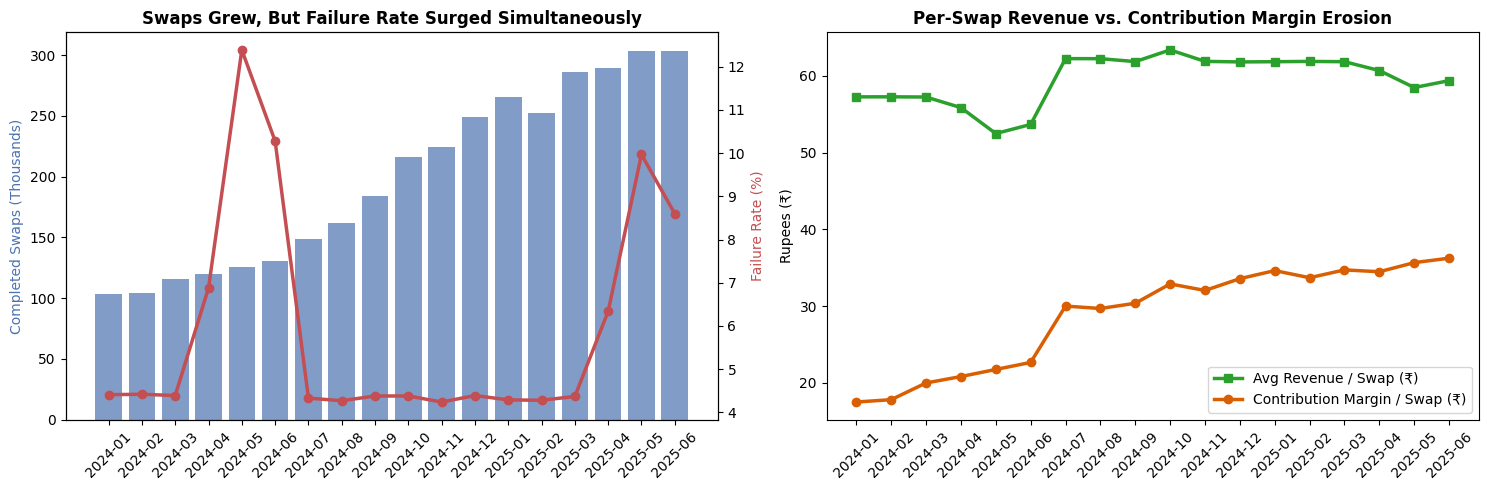

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left chart: Volume vs Failure Rate
a1 = axes[0]
a1.bar(monthly_summary['month'], monthly_summary['completed_swaps'] / 1000, color='#4C72B0', alpha=0.7, label='Completed Swaps (k)')
a1.set_ylabel('Completed Swaps (Thousands)', color='#4C72B0')
a1.tick_params(axis='x', rotation=45)

a1_twin = a1.twinx()
a1_twin.plot(monthly_summary['month'], monthly_summary['failure_rate_pct'], color='#C44E52', marker='o', linewidth=2.5, label='Failure Rate (%)')
a1_twin.set_ylabel('Failure Rate (%)', color='#C44E52')
a1.set_title('Swaps Grew, But Failure Rate Surged Simultaneously', fontsize=12, fontweight='bold')

# Right chart: Revenue per Swap vs Margin per Swap
a2 = axes[1]
a2.plot(monthly_summary['month'], monthly_summary['avg_revenue_per_swap'], marker='s', linewidth=2.5, color='#2CA02C', label='Avg Revenue / Swap (₹)')
a2.plot(monthly_summary['month'], monthly_summary['avg_margin_per_swap'], marker='o', linewidth=2.5, color='#D95F02', label='Contribution Margin / Swap (₹)')
a2.set_ylabel('Rupees (₹)')
a2.tick_params(axis='x', rotation=45)
a2.legend()
a2.set_title('Per-Swap Revenue vs. Contribution Margin Erosion', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

---
## Core Question 2: Service Failures & Customer Experience

Next, I broke down swap outcomes (`swap_completed`, `failed_no_charged_battery`, `abandoned_queue`, etc.) across **vehicle classes (`2W` vs. `3W`)**, **cities**, and **hours of the day**:
* **3W vehicles fail at nearly 2x the rate of 2W (`10.39%` vs. `5.45%`)** (89.61% vs 94.55% completed), driven by higher stockouts (`6.39%`) and queue abandonment (`3.22%`).
* **Failures concentrate in northern cities**—**Jaipur (`7.85%`)**, **Delhi NCR (`7.35%`)**, and **Hyderabad (`6.69%`)**—whereas **Mumbai (`4.45%`)** has the lowest failure rate but the weakest contribution margin (**₹22.94/swap**) due to high rent and electricity tariffs.
* **Evening delivery rush hours** trigger simultaneous surges in queue wait times and stockout failures.

-------------------Swap Outcomes (%) by Vehicle Class (2W vs 3W)--------------------
event_type     abandoned_queue  cancelled_by_rider  failed_no_charged_battery  \
vehicle_class                                                                   
2W                        1.60                0.43                       3.12   
3W                        3.23                0.43                       6.42   

event_type     failed_system_error  swap_completed  
vehicle_class                                       
2W                            0.30           94.55  
3W                            0.31           89.61  

-------------------Performance by City-------------------
        city  total_attempts  failure_rate  avg_wait_sec  avg_margin
0     Jaipur          487444          7.85    243.279999       31.23
1  Delhi NCR          768637          7.35    242.729996       31.18
2  Hyderabad          711746          6.69    242.779999       31.14
3       Pune          552823          4.99 

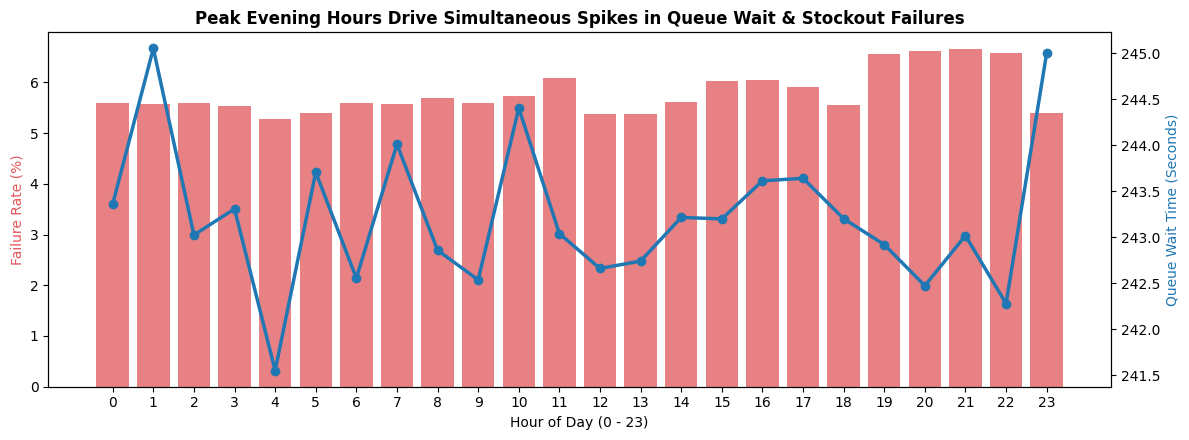

In [17]:
outcome_by_vehicle = pd.crosstab(swaps_full['vehicle_class'],swaps_full['event_type'],normalize='index') * 100
print('-------------------Swap Outcomes (%) by Vehicle Class (2W vs 3W)--------------------')
print(outcome_by_vehicle.round(2))
hourly_perf = swaps_full.groupby('hour').agg(
    attempts=('is_completed', 'count'),
    failure_rate=('is_completed', lambda x: (1 - x.mean()) * 100),
    avg_wait_sec=('queue_wait_sec', 'mean')
).reset_index()
city_perf = swaps_full.groupby('city').agg(
    total_attempts=('is_completed', 'count'),
    failure_rate=('is_completed', lambda x: (1 - x.mean()) * 100),
    avg_wait_sec=('queue_wait_sec', 'mean'),
    avg_margin=('margin_inr', 'mean')
).sort_values('failure_rate', ascending=False).reset_index()

print('\n-------------------Performance by City-------------------')
print(city_perf.round(2))
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(hourly_perf['hour'], hourly_perf['failure_rate'], color='#E15759', alpha=0.75, label='Failure Rate (%)')
ax1.set_xlabel('Hour of Day (0 - 23)')
ax1.set_ylabel('Failure Rate (%)', color='#E15759')
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.plot(hourly_perf['hour'], hourly_perf['avg_wait_sec'], color='#1F77B4', marker='o', linewidth=2.5, label='Avg Queue Wait (sec)')
ax2.set_ylabel('Queue Wait Time (Seconds)', color='#1F77B4')
plt.title('Peak Evening Hours Drive Simultaneous Spikes in Queue Wait & Stockout Failures', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
outcome_by_vehicle = pd.crosstab(swaps_full['vehicle_class'], swaps_full['event_type'], normalize='index') * 100
print('-------------------Swap Outcomes (%) by Vehicle Class-----------------------')
print(outcome_by_vehicle.round(2))
city_perf = swaps_full.groupby('city').agg(
    total_attempts=('is_completed', 'count'),
    failure_rate=('is_completed', lambda x: (1 - x.mean()) * 100),
    avg_wait_sec=('queue_wait_sec', 'mean'),
    avg_rev=('amount_charged_inr', 'mean'),
    avg_margin=('margin_inr', 'mean')
).sort_values('failure_rate', ascending=False).reset_index()
print('\n-------------------------Performance by City----------------------------------')
print(city_perf.round(2))


-------------------Swap Outcomes (%) by Vehicle Class-----------------------
event_type     abandoned_queue  cancelled_by_rider  failed_no_charged_battery  \
vehicle_class                                                                   
2W                        1.60                0.43                       3.12   
3W                        3.23                0.43                       6.42   

event_type     failed_system_error  swap_completed  
vehicle_class                                       
2W                            0.30           94.55  
3W                            0.31           89.61  

-------------------------Performance by City----------------------------------
        city  total_attempts  failure_rate  avg_wait_sec    avg_rev  \
0     Jaipur          487444          7.85    243.279999  57.889999   
1  Delhi NCR          768637          7.35    242.729996  57.959999   
2  Hyderabad          711746          6.69    242.779999  58.320000   
3       Pune          

---
## Core Question 3: Station Hardware & Expansion Wave Patterns

Comparing stations by **charger generation** and **expansion wave** shows that hardware speed is the primary operational bottleneck:
* Legacy **Gen1 stations (51 sites)** suffer a **7.23% failure rate**, whereas **Gen2 (4.85%)** and **Gen3 (4.84%)** reduce failures by **33%**.
* Newer **Wave 1 (`4.88%` failure)** and **Wave 2 (`4.99%` failure, `₹35.62` margin)** stations outperform the original **90 Launch stations (`6.24%` failure)** because most Launch sites still rely on Gen1 chargers.

In [19]:
# --------- Core Question 3: Performance by Charger Generation (Gen1 vs Gen2 vs Gen3) --------------
gen_perf = swaps_full.groupby('charger_generation').agg(
    stations=('station_id', 'nunique'),
    attempts=('is_completed', 'count'),
    failure_rate=('is_completed', lambda x: (1 - x.mean()) * 100),
    avg_wait_sec=('queue_wait_sec', 'mean'),
    avg_margin=('margin_inr', 'mean')
).reset_index()
print('\n--------------------------Performance by Charger Generation----------------------------')
print(gen_perf.round(2))
wave_perf = swaps_full.groupby('expansion_wave').agg(
    stations=('station_id', 'nunique'),
    attempts=('is_completed', 'count'),
    swaps_per_station=('is_completed', lambda x: x.sum() / len(x) * 100),
    failure_rate=('is_completed', lambda x: (1 - x.mean()) * 100),
    avg_wait_sec=('queue_wait_sec', 'mean'),
    avg_margin=('margin_inr', 'mean')
).reset_index()
print('-------------------------------Performance by Expansion Wave------------------------------')
print(wave_perf.round(2))


--------------------------Performance by Charger Generation----------------------------
  charger_generation  stations  attempts  failure_rate  avg_wait_sec  \
0               Gen1        51   1821530          7.23    242.919998   
1               Gen2        62   1620327          4.85    242.949997   
2               Gen3        37    372138          4.84    243.080002   

   avg_margin  
0       30.83  
1       30.15  
2       35.46  
-------------------------------Performance by Expansion Wave------------------------------
  expansion_wave  stations  attempts  swaps_per_station  failure_rate  \
0         Launch        90   3068065              93.76          6.24   
1   Wave1_2024H2        30    500944              95.12          4.88   
2   Wave2_2025H1        30    244986              95.01          4.99   

   avg_wait_sec  avg_margin  
0    242.940002       30.49  
1    242.869995       31.81  
2    243.229996       35.62  


---
## Core Question 4: Battery Health & Supplier Lifecycle Analysis

By linking `batteries.csv` to completed swap counts, I calculated lifetime swaps delivered and depreciation cost per swap (`purchase_cost_inr / total_swaps_delivered`) across suppliers:
* **Kyron 2W Defect:** **100% of Kyron 2W packs (1,385 / 1,385)** retired prematurely at **60.53% SOH** after delivering only **401.55 swaps** on average—compared to **643.0 swaps** for Cellora and Amptek (`0` retired). This raised battery wear cost from **₹49.82/swap** to **₹79.85/swap (+62%)**.
* **Range Degradation:** When 2W battery SOH falls below **70%**, average delivered range drops **33.5% (from 65.05 km to 43.26 km)**, forcing riders to swap 50% more often.

In [20]:
# --- CORE QUESTION 4: BATTERY SUPPLIER & HEALTH ANALYSIS ---
bat_swaps = (
    swaps_full[swaps_full['is_completed'] == 1]
    .groupby('battery_out_id')
    .size()
    .rename('total_swaps_delivered')
)
bat_analysis = batteries.merge(bat_swaps, left_on='battery_id', right_index=True, how='left')
bat_analysis['total_swaps_delivered'] = bat_analysis['total_swaps_delivered'].fillna(0)
bat_analysis['soh_drop'] = bat_analysis['initial_soh_pct'] - bat_analysis['current_soh_pct']
bat_analysis['wear_cost_per_swap'] = np.where(
    bat_analysis['total_swaps_delivered'] > 0,
    bat_analysis['purchase_cost_inr'] / bat_analysis['total_swaps_delivered'],
    np.nan
)

supplier_summary = bat_analysis.groupby(['pack_type', 'supplier']).agg(
    total_packs=('battery_id', 'count'),
    retired_packs=('retired_date', lambda x: x.notna().sum()),
    avg_current_soh=('current_soh_pct', 'mean'),
    avg_swaps=('total_swaps_delivered', 'mean'),
    avg_wear_cost_inr=('wear_cost_per_swap', 'mean')
).reset_index()
print('-------------------------Battery Performance by Supplier----------------------------')
print(supplier_summary.round(2))
swaps_full['soh_bucket'] = pd.cut(swaps_full['soh_out_pct'], bins=[0, 70, 80, 90, 100], labels=['<70%', '70-80%', '80-90%', '90-100%'])
range_by_soh = swaps_full[swaps_full['is_completed'] == 1].groupby(['vehicle_class', 'soh_bucket'], observed=True)['clean_km'].mean().unstack()
print('---------------Average Delivered Range (km) by Battery Health (SOH)---------------------')
print(range_by_soh.round(2))


-------------------------Battery Performance by Supplier----------------------------
   pack_type supplier  total_packs  retired_packs  avg_current_soh  avg_swaps  \
0  2W_2.1kWh   Amptek         1098              0            79.96     642.89   
1  2W_2.1kWh  Cellora         3035              0            79.97     643.00   
2  2W_2.1kWh    Kyron         1385           1385            60.53     401.55   
3  3W_4.8kWh   Amptek          209              0            86.51     377.33   
4  3W_4.8kWh  Cellora          520              0            86.52     378.61   
5  3W_4.8kWh    Kyron          253             53            81.35     381.34   

   avg_wear_cost_inr  
0              49.85  
1              49.82  
2              79.85  
3             180.22  
4             179.92  
5             178.60  
---------------Average Delivered Range (km) by Battery Health (SOH)---------------------
soh_bucket          <70%     70-80%     80-90%    90-100%
vehicle_class                          

---
## Core Question 5: Pricing Pilot & Fleet Partner Economics

Evaluating tariff codes and B2B partner contracts reveals a major volume-versus-margin disconnect:
* **Peak/Off-Peak Pilot:** `PEAK` pricing delivers **₹53.40 gross margin/swap** (`₹82.55` charged) compared to `STD` (**₹34.06**) and `OFFPEAK` (**₹30.37**).
* **The ZipDrop Paradox:** Largest fleet partner **ZipDrop (`FP-03`)** drives **549,161 swaps** (#1 in volume, ahead of FeastFly at 516,227) but generates the **lowest gross margin on the network (`₹20.08/swap` before battery wear)**—over 50% lower than **FeastFly (`FP-01`, `₹30.37/swap`)**.

In [21]:
# --- CORE QUESTION 5: PRICING & PARTNER ECONOMICS ---
tariff_summary = swaps_full[swaps_full['is_completed'] == 1].groupby('tariff_code', observed=True).agg(
    completed_swaps=('is_completed', 'count'),
    avg_list_price=('list_price_inr', 'mean'),
    avg_discount=('discount_inr', 'mean'),
    avg_charged=('amount_charged_inr', 'mean'),
    avg_margin=('margin_inr', 'mean')
).reset_index()
print('----------------------------Revenue & Margin by Tariff Code---------------------------')
print(tariff_summary.round(2))
partner_swaps = swaps_full[(swaps_full['is_completed'] == 1) & (swaps_full['partner_id'].notna())].copy()
partner_swaps = partner_swaps.merge(partners[['partner_id', 'partner_name', 'partner_segment', 'discount_pct', 'discount_pct_after_amendment']], on='partner_id', how='left')

partner_perf = partner_swaps.groupby(['partner_id', 'partner_name', 'partner_segment']).agg(
    completed_swaps=('is_completed', 'count'),
    total_revenue=('amount_charged_inr', 'sum'),
    avg_charged=('amount_charged_inr', 'mean'),
    avg_margin=('margin_inr', 'mean')
).sort_values('completed_swaps', ascending=False).reset_index()
print('-----------------------Fleet Partner Volume vs. Margin per Swap----------------------')
print(partner_perf.round(2))


----------------------------Revenue & Margin by Tariff Code---------------------------
  tariff_code  completed_swaps  avg_list_price  avg_discount  avg_charged  \
0     OFFPEAK            34833       67.480003          0.00    59.480000   
1     PARTNER          2367472       69.699997          8.81    61.689999   
2        PEAK           163899       67.500000          0.00    82.500000   
3         STD          1019552       66.209999          0.00    66.209999   

   avg_margin  
0       30.37  
1       28.13  
2       53.40  
3       34.06  
-----------------------Fleet Partner Volume vs. Margin per Swap----------------------
   partner_id partner_name partner_segment  completed_swaps  total_revenue  \
0       FP-03      ZipDrop  quick_commerce           549161     28595038.0   
1       FP-01     FeastFly   food_delivery           516227     32019300.0   
2       FP-02   ParcelNest  ecom_logistics           296162     16737546.0   
3       FP-05   Swiggle Go   food_delivery       

#### Impact of ZipDrop's November 1, 2024 Contract Renegotiation
Splitting ZipDrop's swaps before and after `2024-11-01` confirms that raising its contracted discount from **12% to 28%** (while waiving peak surcharges) dropped average revenue per swap from **₹57.48 to ₹48.64** and compressed gross contribution margin to **₹19.26/swap**—leaving every swap cash-negative once battery depreciation (`₹49–₹79/swap`) is accounted for.

In [22]:
zipdrop = swaps_full[(swaps_full['partner_id'] == 'FP-03') & (swaps_full['is_completed'] == 1)].copy()
zipdrop['period'] = np.where(zipdrop['event_ts'] < '2024-11-01', 'Before Amendment (12% disc)', 'After Amendment (28% disc)')
print('------------------ZipDrop Before vs. After Nov 2024 Renegotiation------------------------')
print(zipdrop.groupby('period').agg(
    swaps=('is_completed', 'count'),
    avg_charged=('amount_charged_inr', 'mean'),
    avg_margin=('margin_inr', 'mean')
).round(2))

------------------ZipDrop Before vs. After Nov 2024 Renegotiation------------------------
                              swaps  avg_charged  avg_margin
period                                                      
After Amendment (28% disc)   336249    48.639999       19.26
Before Amendment (12% disc)  212912    57.480000       21.38


---
## Core Question 6: Root Cause Analysis of New-Rider Retention

To identify why new riders churn, I tracked each rider's **first 5 swap attempts** (filtering out signups after May 15, 2025 so every cohort had at least 30 days of observation) and compared riders who stayed active for **30+ days** against early churners.

In [23]:
swaps_sorted = swaps_full.sort_values(['rider_id', 'event_ts'])
rider_activity = swaps_sorted.groupby('rider_id').agg(
    first_attempt=('event_ts', 'min'),
    last_attempt=('event_ts', 'max'),
    total_attempts=('is_completed', 'count'),
    completed_swaps=('is_completed', 'sum'),
    first_5_failures=('is_completed', lambda x: (1 - x.head(5)).sum()),
    avg_wait_first_5=('queue_wait_sec', lambda x: x.head(5).mean()),
    avg_soh_first_5=('soh_out_pct', lambda x: x.head(5).mean())
).reset_index()
rider_cohort = riders[riders['signup_date'] <= '2025-05-15'].merge(rider_activity, on='rider_id', how='left')
rider_cohort['completed_swaps'] = rider_cohort['completed_swaps'].fillna(0)
rider_cohort['active_span_days'] = (rider_cohort['last_attempt'] - rider_cohort['first_attempt']).dt.days.fillna(0)
rider_cohort['is_retained_30d'] = (rider_cohort['active_span_days'] >= 30).astype(int)


#### Primary vs. Secondary Drivers of Rider Churn
* **Primary Driver — Early Stockout Exposure:** Riders who experienced **1 or more failures in their first 5 attempts** had a **30-day retention rate of 88.34%** vs. **91.40%** for failure-free riders (**38.7% higher early churn**), and churned riders averaged **46% more early failures (`0.37` vs. `0.27`)**. City retention mirrors failure rates, lowest in **Jaipur (`88.88%`)** and **Delhi NCR (`89.87%`)**.
* **Secondary Contributors — Battery SOH & Support Friction:** Churned riders received lower-SOH batteries in their first 5 swaps (**90.78% vs. 92.55%**). Meanwhile, **44,000 support tickets** are dominated by `no_battery_available` (**11,647 tickets**) and `other` (**9,484 tickets**, containing misclassified Hinglish battery complaints), with **5,175 tickets still unresolved**.

In [24]:
print('\n----------------Core Question 6: Retained (30+ Days) vs. Early Churned Riders--------------------')
retention_drivers = rider_cohort.groupby('is_retained_30d').agg(
    rider_count=('rider_id', 'count'),
    avg_first5_failures=('first_5_failures', 'mean'),
    avg_first5_wait_sec=('avg_wait_first_5', 'mean'),
    avg_soh_first_5=('avg_soh_first_5', 'mean')
).round(2)
print(retention_drivers)

rider_cohort['had_early_failure'] = np.where(
    rider_cohort['first_5_failures'] >= 1,
    'Yes (1+ failure in first 5)',
    'No (0 failures in first 5)'
)
print('\n----------------30-Day Retention Rate (%) by Early Failure Experience-------------------')
print((rider_cohort.groupby('had_early_failure')['is_retained_30d'].mean() * 100).round(2))
print('\n----------------30-Day Retention Rate (%) by Plan Type & Vehicle Class-------------------')
print((rider_cohort.groupby(['plan_type', 'vehicle_class'])['is_retained_30d'].mean() * 100).unstack().round(2))
print('\n----------------30-Day Retention Rate (%) by City-------------------')
print((rider_cohort.groupby('home_city')['is_retained_30d'].mean() * 100).sort_values().round(2))
print('\n----------------Support Tickets by Category & Resolution Status-------------------')
print(pd.crosstab(tickets['category'], tickets['resolution_status'], margins=True))


----------------Core Question 6: Retained (30+ Days) vs. Early Churned Riders--------------------
                 rider_count  avg_first5_failures  avg_first5_wait_sec  \
is_retained_30d                                                          
0                       1686                 0.37           241.869995   
1                      16403                 0.27           241.800003   

                 avg_soh_first_5  
is_retained_30d                   
0                          90.77  
1                          92.55  

----------------30-Day Retention Rate (%) by Early Failure Experience-------------------
had_early_failure
No (0 failures in first 5)     91.40
Yes (1+ failure in first 5)    88.34
Name: is_retained_30d, dtype: float64

----------------30-Day Retention Rate (%) by Plan Type & Vehicle Class-------------------
vehicle_class      2W     3W
plan_type                   
partner_billed  90.64  89.29
pay_as_you_go   91.36  91.65
prepaid_pack    90.66  89.33

-------

---
## Summary Visualizations for Executive Report

Finally, I generated and exported four high-resolution charts summarizing:
1. **Monthly Swap Growth vs. Summer Failure Spikes**
2. **City-Level Failure Rate vs. Margin Trade-Off**
3. **Kyron 2W Depreciation Cost & SOH Range Loss**
4. **Fleet Partner Volume vs. Contribution Margin Paradox**

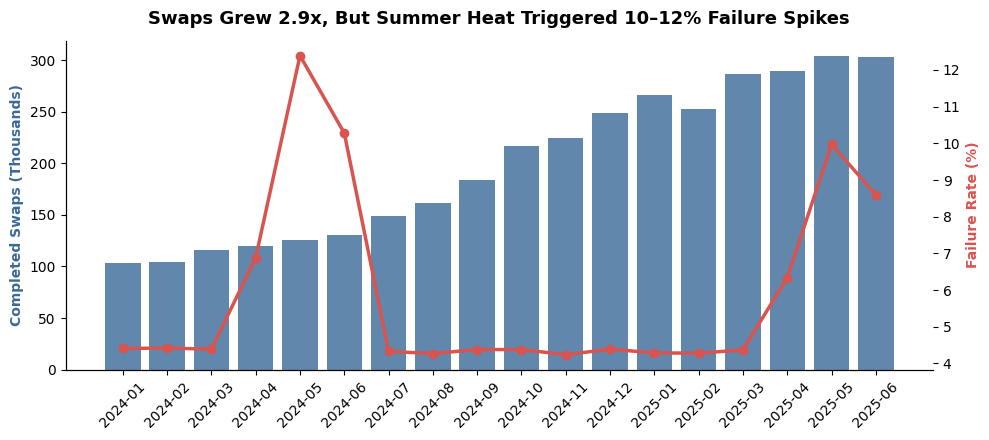

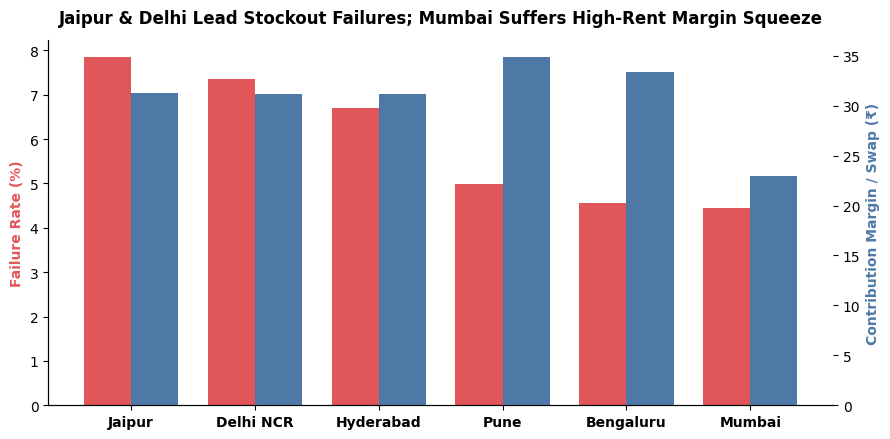

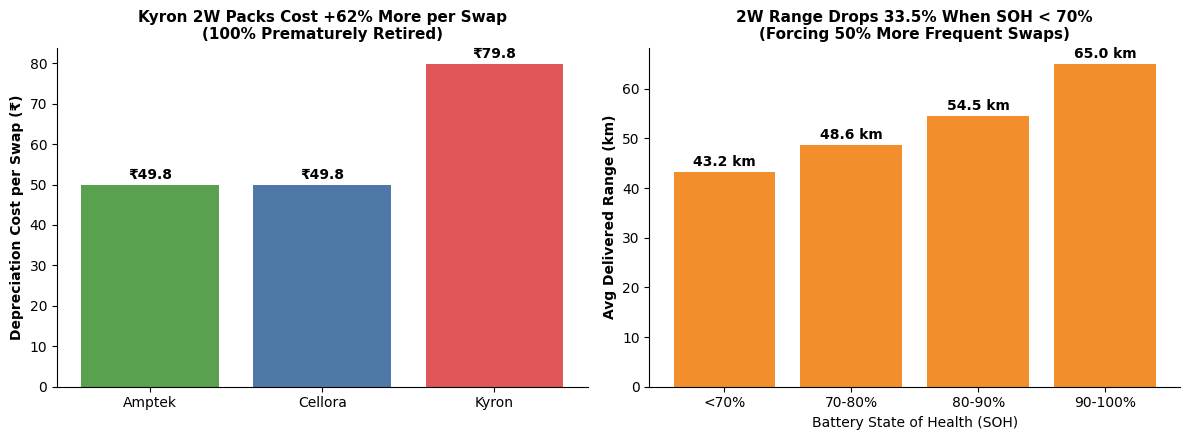

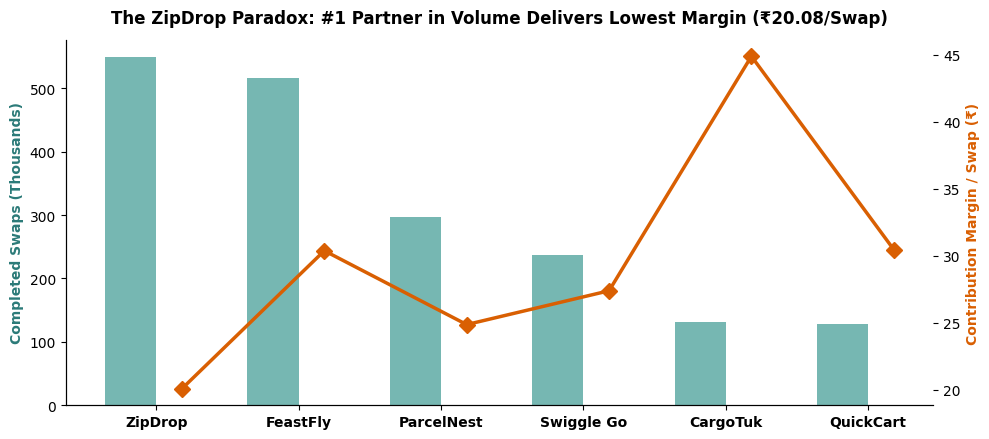

All 4 charts saved to: /content/drive/MyDrive/voltreplay_clean


In [25]:
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# --- CHART 1: Monthly Swaps vs Summer Failure Spikes ---
fig, a = plt.subplots(figsize=(10, 4.5))
a.bar(monthly_summary['month'], monthly_summary['completed_swaps'] / 1000, color='#3B6998', alpha=0.8, label='Completed Swaps (k)')
a.set_ylabel('Completed Swaps (Thousands)', color='#3B6998', fontweight='bold')
a.tick_params(axis='x', rotation=45)

b = a.twinx()
b.spines['top'].set_visible(False)
b.plot(monthly_summary['month'], monthly_summary['failure_rate_pct'], color='#D9534F', marker='o', linewidth=2.5, label='Failure Rate (%)')
b.set_ylabel('Failure Rate (%)', color='#D9534F', fontweight='bold')
plt.title('Swaps Grew 2.9x, But Summer Heat Triggered 10–12% Failure Spikes', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(f"{save_folder}/chart1_monthly_trends.png", dpi=300)
plt.show()

# --- CHART 2: City Failure Rate vs Contribution Margin ---
fig,c = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(city_perf))
width = 0.38
c.bar(x - width/2, city_perf['failure_rate'], width, color='#E15759', label='Failure Rate (%)')
c.set_ylabel('Failure Rate (%)', color='#E15759', fontweight='bold')
c.set_xticks(x)
c.set_xticklabels(city_perf['city'], fontweight='bold')

d = c.twinx()
d.spines['top'].set_visible(False)
d.bar(x + width/2, city_perf['avg_margin'], width, color='#4E79A7', label='Margin / Swap (₹)')
d.set_ylabel('Contribution Margin / Swap (₹)', color='#4E79A7', fontweight='bold')
plt.title('Jaipur & Delhi Lead Stockout Failures; Mumbai Suffers High-Rent Margin Squeeze', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(f"{save_folder}/chart2_city_tradeoff.png", dpi=300)
plt.show()

# --- CHART 3: Battery Supplier Wear Cost & Range Drop ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
w2_sup = supplier_summary[supplier_summary['pack_type'] == '2W_2.1kWh']
colors_sup = ['#59A14F', '#4E79A7', '#E15759']
axes[0].bar(w2_sup['supplier'], w2_sup['avg_wear_cost_inr'], color=colors_sup)
axes[0].set_ylabel('Depreciation Cost per Swap (₹)', fontweight='bold')
axes[0].set_title('Kyron 2W Packs Cost +62% More per Swap\n(100% Prematurely Retired)', fontsize=11, fontweight='bold')
for i, v in enumerate(w2_sup['avg_wear_cost_inr']):
    axes[0].text(i, v + 1.5, f"₹{v:.1f}", ha='center', fontweight='bold')

w2_range = range_by_soh.loc['2W']
axes[1].bar(w2_range.index.astype(str), w2_range.values, color='#F28E2B')
axes[1].set_ylabel('Avg Delivered Range (km)', fontweight='bold')
axes[1].set_xlabel('Battery State of Health (SOH)')
axes[1].set_title('2W Range Drops 33.5% When SOH < 70%\n(Forcing 50% More Frequent Swaps)', fontsize=11, fontweight='bold')
for i, v in enumerate(w2_range.values):
    axes[1].text(i, v + 1.2, f"{v:.1f} km", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(f"{save_folder}/chart3_battery_kyron.png", dpi=300)
plt.show()

# --- CHART 4: Top Fleet Partners Volume vs Margin per Swap ---
top6 = partner_perf.head(6)
fig, e = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(top6))
e.bar(x - 0.18, top6['completed_swaps'] / 1000, 0.36, color='#76B7B2', label='Completed Swaps (k)')
e.set_ylabel('Completed Swaps (Thousands)', color='#2B7A78', fontweight='bold')
e.set_xticks(x)
e.set_xticklabels(top6['partner_name'], fontweight='bold')

f = e.twinx()
f.spines['top'].set_visible(False)
f.plot(x + 0.18, top6['avg_margin'], color='#D95F02', marker='D', markersize=8, linewidth=2.5, label='Margin / Swap (₹)')
f.set_ylabel('Contribution Margin / Swap (₹)', color='#D95F02', fontweight='bold')
plt.title('The ZipDrop Paradox: #1 Partner in Volume Delivers Lowest Margin (₹20.08/Swap)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(f"{save_folder}/chart4_partner_economics.png", dpi=300)
plt.show()
print("All 4 charts saved to:", save_folder)

DEEP-DIVE QUESTIONS

In [26]:
completed_swaps = swaps_full[swaps_full['is_completed'] == 1].copy()
wear_info = bat_analysis[['battery_id', 'supplier', 'manufacturing_lot', 'wear_cost_per_swap']]
completed_swaps = completed_swaps.merge(wear_info, left_on='battery_out_id', right_on='battery_id', how='left')
completed_swaps['net_margin_inr'] = completed_swaps['margin_inr'] - completed_swaps['wear_cost_per_swap']
partner_swaps = completed_swaps[completed_swaps['partner_id'].notna()].copy()
partner_swaps = partner_swaps.merge(partners[['partner_id', 'partner_name', 'partner_segment']], on='partner_id', how='left')
partner_profit = partner_swaps.groupby(['partner_name', 'partner_segment'], as_index=False).agg(
    total_swaps=('is_completed', 'count'),
    margin_before_wear=('margin_inr', 'mean'),
    battery_wear=('wear_cost_per_swap', 'mean'),
    true_net_margin=('net_margin_inr', 'mean'),
    total_net_profit=('net_margin_inr', 'sum')
)

partner_profit = partner_profit.sort_values('total_swaps', ascending=False)
print(partner_profit.round(2))

   partner_name partner_segment  total_swaps  margin_before_wear  \
11      ZipDrop  quick_commerce       549161               20.08   
2      FeastFly   food_delivery       516227               30.37   
6    ParcelNest  ecom_logistics       296162               24.86   
9    Swiggle Go   food_delivery       237569               27.39   
0      CargoTuk        cargo_3w       131316               44.88   
7     QuickCart  quick_commerce       127908               30.46   
8     RideMitra       bike_taxi       119457               30.94   
1   DabbaXpress   food_delivery        91998               32.34   
10  UrbanErrand       bike_taxi        82337               31.33   
5     MetroMove  ecom_logistics        81906               27.07   
4   LastMileHub  ecom_logistics        80320               29.10   
3      HaulKing        cargo_3w        53111               45.72   

    battery_wear  true_net_margin  total_net_profit  
11         62.36           -42.27      -23215673.33  
2      

In [27]:
print('Stations by city and wave: ')
print(pd.crosstab(stations['city'], stations['expansion_wave'], margins=True))
wave_check = swaps_full.groupby(['city', 'expansion_wave'], as_index=False).agg(
    num_stations=('station_id', 'nunique'),
    total_attempts=('is_completed', 'count'),
    completed=('is_completed', 'sum'),
    avg_fixed_cost=('fixed_cost_per_swap', 'mean')
)
wave_check['failure_rate'] = (1 - wave_check['completed'] / wave_check['total_attempts']) * 100
wave_check['attempts_per_station'] = wave_check['total_attempts'] / wave_check['num_stations']
print('\nWave performance by city: ')
print(wave_check[['city', 'expansion_wave', 'num_stations', 'attempts_per_station', 'failure_rate', 'avg_fixed_cost']].round(2))

Stations by city and wave: 
expansion_wave  Launch  Wave1_2024H2  Wave2_2025H1  All
city                                                   
Bengaluru           20             6             6   32
Delhi NCR           18             6             6   30
Hyderabad           16             5             5   26
Jaipur              10             4             4   18
Mumbai              13             4             5   22
Pune                13             5             4   22
All                 90            30            30  150

Wave performance by city: 
         city expansion_wave  num_stations  attempts_per_station  \
0   Bengaluru         Launch            20              31949.80   
1   Bengaluru   Wave1_2024H2             6              14216.00   
2   Bengaluru   Wave2_2025H1             6               6482.67   
3   Delhi NCR         Launch            18              34627.28   
4   Delhi NCR   Wave1_2024H2             6              14673.50   
5   Delhi NCR   Wave2_2025H1    

In [28]:
comments = tickets['rider_comment'].fillna('').str.lower()
actual_issue = []
for text in comments:
    if any(word in text for word in ['weak', 'discharge', 'range', 'battery', 'battry', 'drain']):
        actual_issue.append('battery_or_range')
    elif any(word in text for word in ['queue', 'wait', 'lamba', 'late', 'empty', 'nahi mila']):
        actual_issue.append('stockout_or_queue')
    elif any(word in text for word in ['amount', 'kata', 'surcharge', 'extra', 'bill']):
        actual_issue.append('billing')
    else:
        actual_issue.append('other')

tickets['actual_issue'] = actual_issue
print('Agent category vs actual rider comment: ')
print(pd.crosstab(tickets['category'], tickets['actual_issue'], margins=True))

Agent category vs actual rider comment: 
actual_issue          battery_or_range  billing  other  stockout_or_queue  \
category                                                                    
app_issue                            0        0   5787                  0   
billing_dispute                      0     4715      0                  0   
long_queue                           0        0   1899               3832   
low_range                         4744        0   1892                  0   
no_battery_available              8714        0      0               2933   
other                             3057        0   6427                  0   
All                              16515     4715  16005               6765   

actual_issue            All  
category                     
app_issue              5787  
billing_dispute        4715  
long_queue             5731  
low_range              6636  
no_battery_available  11647  
other                  9484  
All                   440

In [29]:
#Top 10 worst stations (with at least 5,000 swap attempts)
st_summary = swaps_full.groupby(['station_id', 'city', 'charger_generation', 'connectivity_tier'], as_index=False).agg(
    attempts=('is_completed', 'count'),
    completed=('is_completed', 'sum'),
    avg_wait=('queue_wait_sec', 'mean')
)
st_summary['failure_rate'] = (1 - st_summary['completed'] / st_summary['attempts']) * 100

busy_stations = st_summary[st_summary['attempts'] >= 5000]
print('Top 10 highest-failure stations: ')
print(busy_stations.sort_values('failure_rate', ascending=False).head(10).round(2))

#Check Kyron manufacturing lots
kyron_only = bat_analysis[bat_analysis['supplier'] == 'Kyron'].copy()
kyron_only['is_retired'] = kyron_only['retired_date'].notna()

lot_summary = kyron_only.groupby(['pack_type', 'manufacturing_lot'], as_index=False).agg(
    total_packs=('battery_id', 'count'),
    retired_packs=('is_retired', 'sum'),
    avg_soh=('current_soh_pct', 'mean'),
    avg_swaps=('total_swaps_delivered', 'mean')
)
print('\nKyron lot breakdown: ')
print(lot_summary.round(2))

#Connectivity tier vs failure rate and offline syncs
swaps_full['is_offline'] = (swaps_full['sync_mode'] == 'offline_batch').astype(int)

conn_summary = swaps_full.groupby('connectivity_tier', as_index=False).agg(
    stations=('station_id', 'nunique'),
    attempts=('is_completed', 'count'),
    completed=('is_completed', 'sum'),
    offline_pct=('is_offline', 'mean')
)
conn_summary['failure_rate'] = (1 - conn_summary['completed'] / conn_summary['attempts']) * 100
conn_summary['offline_pct'] = conn_summary['offline_pct'] * 100

print('\nConnectivity tier impact: ')
print(conn_summary[['connectivity_tier', 'stations', 'attempts', 'failure_rate', 'offline_pct']].round(2))

Top 10 highest-failure stations: 
     station_id       city charger_generation connectivity_tier  attempts  \
36  STN-DEL-037  Delhi NCR               Gen1              good     30838   
47  STN-DEL-048  Delhi NCR               Gen1              good     34646   
92  STN-JAI-137     Jaipur               Gen1              fair     44335   
97  STN-JAI-142     Jaipur               Gen1              poor     33299   
96  STN-JAI-141     Jaipur               Gen1              good     45594   
44  STN-DEL-045  Delhi NCR               Gen1              good     32237   
91  STN-JAI-136     Jaipur               Gen1              good     29340   
93  STN-JAI-138     Jaipur               Gen1              poor     48904   
39  STN-DEL-040  Delhi NCR               Gen1              fair     40307   
49  STN-DEL-050  Delhi NCR               Gen1              poor     47008   

    completed    avg_wait  failure_rate  
36      28039  242.639999          9.08  
47      31535  243.990005         

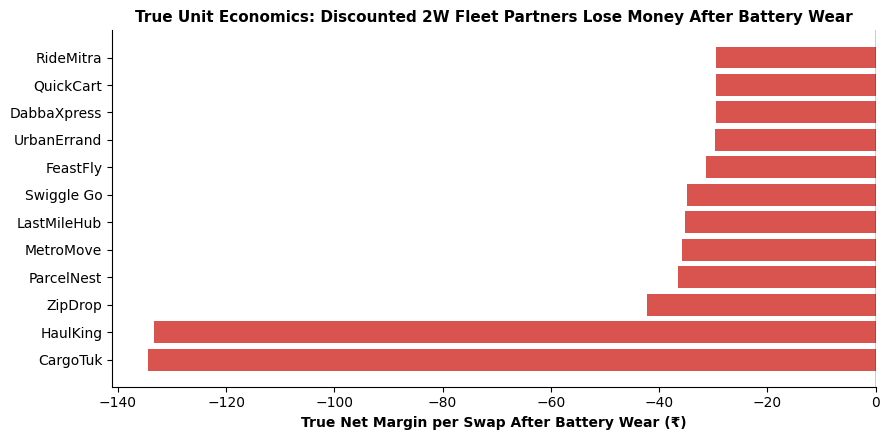

In [30]:
completed_swaps = swaps_full[swaps_full['is_completed'] == 1].copy()
wear_info = bat_analysis[['battery_id', 'wear_cost_per_swap']]
completed_swaps = completed_swaps.merge(wear_info, left_on='battery_out_id', right_on='battery_id', how='left')
completed_swaps['net_margin_inr'] = completed_swaps['margin_inr'] - completed_swaps['wear_cost_per_swap']

partner_net = completed_swaps[completed_swaps['partner_id'].notna()].merge(partners[['partner_id', 'partner_name']], on='partner_id', how='left')
net_summary = partner_net.groupby('partner_name', as_index=False)['net_margin_inr'].mean().sort_values('net_margin_inr')

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#D9534F' if val < 0 else '#4E79A7' for val in net_summary['net_margin_inr']]
ax.barh(net_summary['partner_name'], net_summary['net_margin_inr'], color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('True Net Margin per Swap After Battery Wear (₹)', fontweight='bold')
ax.set_title('True Unit Economics: Discounted 2W Fleet Partners Lose Money After Battery Wear', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{save_folder}/chart5_deep_dive.png", dpi=300)
plt.show()